In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from typing import Tuple
from tqdm import tqdm
import pandas as pd

### Simulación del potencial de una neurona mediante el modelo computacional de Izhikevich.

Función `izhikevich` contiene la dinámica de evolución del potencial de una membrana siguiendo el esquema propuesto por Izhikevich. El sistema bidimensional de ecuaciones diferenciales ordinarias se resuelve numéricamente a partir de Euler explícito.

In [13]:
def izhikevich(
    a: float = 0.02,
    b: float = 0.25,
    c: float = -65.0,
    d: float = 2.0,
    T: float = 200,
    dt: float = 0.5,
    plot: bool = True,
) -> Tuple[np.ndarray, np.ndarray]:

    """ 
         The two-dimensional system of ordinary differential equations is solved numerically using the explicit Euler method.

    
    Parameters
    ----------
    T :
        Total simulation time.

    dt :
        Time step.

    a, b, c, d:
        Parameters of the model.
        
    plot :
        If True, display the simulation plot. If False, no plot is shown.

    Returns
    -------
    V: Membrane potential of the neuron.
    I: Input current

    """
    # ======================
    # TIEMPO
    # ======================
    N = int(T / dt)
    t_inicio_estimulo = 70.0
    n_inicio = int(t_inicio_estimulo / dt)

    # ======================
    # CORRIENTE DE ENTRADA
    # ======================
    I = np.zeros(N)
    I[n_inicio:] = 5.0  

    # ======================
    # INICIALIZACIÓN
    # ======================
    v = np.zeros(N)
    u = np.zeros(N)

    A_quad = 0.04
    B_quad = 5.0 - b
    C_quad = 140.0
    v_equilibrio = (-B_quad - np.sqrt(B_quad**2 - 4 * A_quad * C_quad)) / (2 * A_quad)
    
    v[0] = v_equilibrio
    u[0] = b * v[0]

    # ======================    
    # BUCLE DE INTEGRACIÓN
    # ======================
    for t in range(1, N):
        v_ant = v[t-1]
        u_ant = u[t-1]
        
        dv = (0.04 * v_ant**2 + 5.0 * v_ant + 140.0 - u_ant + I[t-1]) * dt
        du = (a * (b * v_ant - u_ant)) * dt
        
        v[t] = v_ant + dv
        u[t] = u_ant + du
        
        if v[t] >= 30.0:
            v[t-1] = 30.0
            v[t] = c
            u[t] = u[t] + d
            
    tiempo = np.arange(0, T, dt)
    return tiempo, v, I

Patrones clásicos descritos en Izhikevich 2003: "Simple model of spiking neurons":

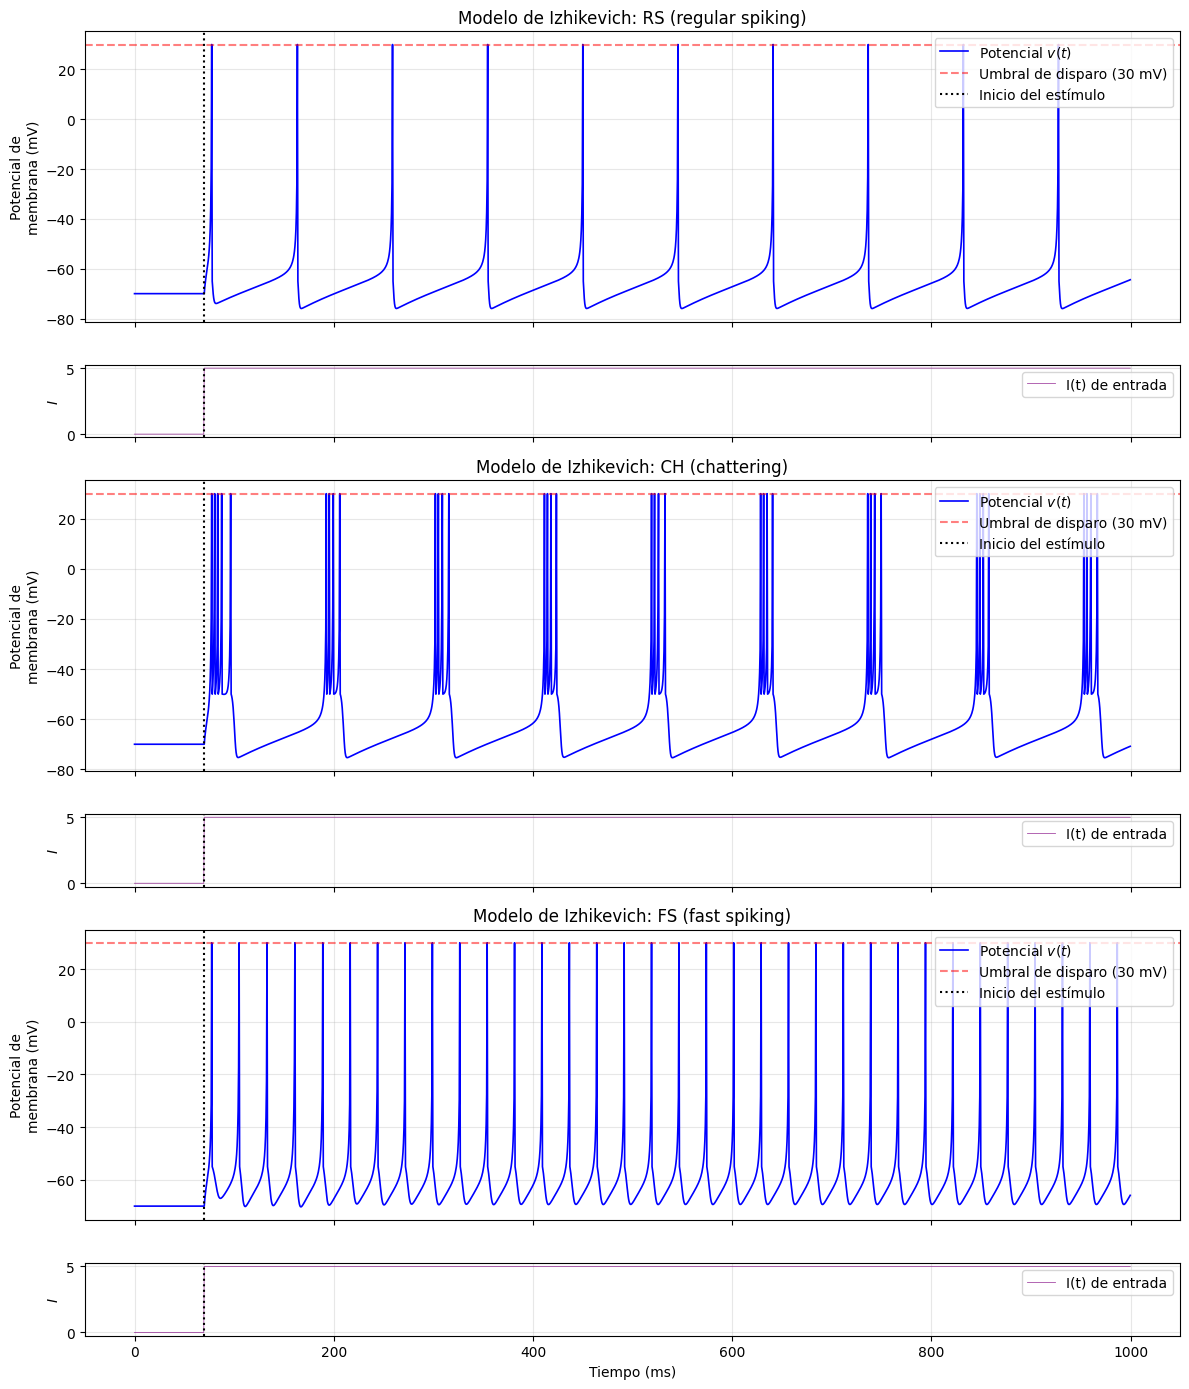

In [20]:
parametros = [
    {"titulo": "RS (regular spiking)", 'a': 0.02, 'b': 0.2, 'c': -65.0, 'd': 8.0},
    {"titulo": "CH (chattering)", 'a': 0.02, 'b': 0.2, 'c': -50.0, 'd': 2.0},
    {"titulo": "FS (fast spiking)", 'a': 0.1,  'b': 0.2, 'c': -55.0, 'd': 4.0}
]

T = 1000
dt = 0.5
t_inicio_estimulo = 70.0

fig, axes = plt.subplots(6, 1, figsize=(12, 14), sharex=True, gridspec_kw={'height_ratios': [4, 1, 4, 1, 4, 1]})

for i, p in enumerate(parametros):
    tiempo, v, I = izhikevich(a=p['a'], b=p['b'], c=p['c'], d=p['d'], T=T, dt=dt)
    ax_v = axes[2*i]
    ax_I = axes[2*i + 1]

    ax_v.plot(tiempo, v, color='blue', lw=1.2, label='Potencial $v(t)$')
    ax_v.axhline(30, color='red', linestyle='--', alpha=0.5, label='Umbral de disparo (30 mV)')
    ax_v.axvline(t_inicio_estimulo, color='black', linestyle=':', label='Inicio del estímulo')
    ax_v.set_ylabel('Potencial de\nmembrana (mV)')
    ax_v.set_title(f"Modelo de Izhikevich: {p['titulo']}")
    ax_v.grid(True, alpha=0.3)
    ax_v.legend(loc='upper right')
    ax_I.plot(tiempo, I, color='purple', lw=0.6, alpha=0.7, label='I(t) de entrada')
    ax_I.axvline(t_inicio_estimulo, color='black', linestyle=':')
    ax_I.set_ylabel('$I$')
    ax_I.grid(True, alpha=0.3)
    ax_I.legend(loc='upper right')

axes[-1].set_xlabel('Tiempo (ms)')
plt.tight_layout()
plt.show()

Dinámicas de grupos neuronales presentes en el sistema electromotor del pez eléctrico, descritos en "Modeling the sequential pattern variability of the electromotor command system of pulse electric fish":

C:\Users\alons\AppData\Local\Temp\ipykernel_20448\3090861370.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


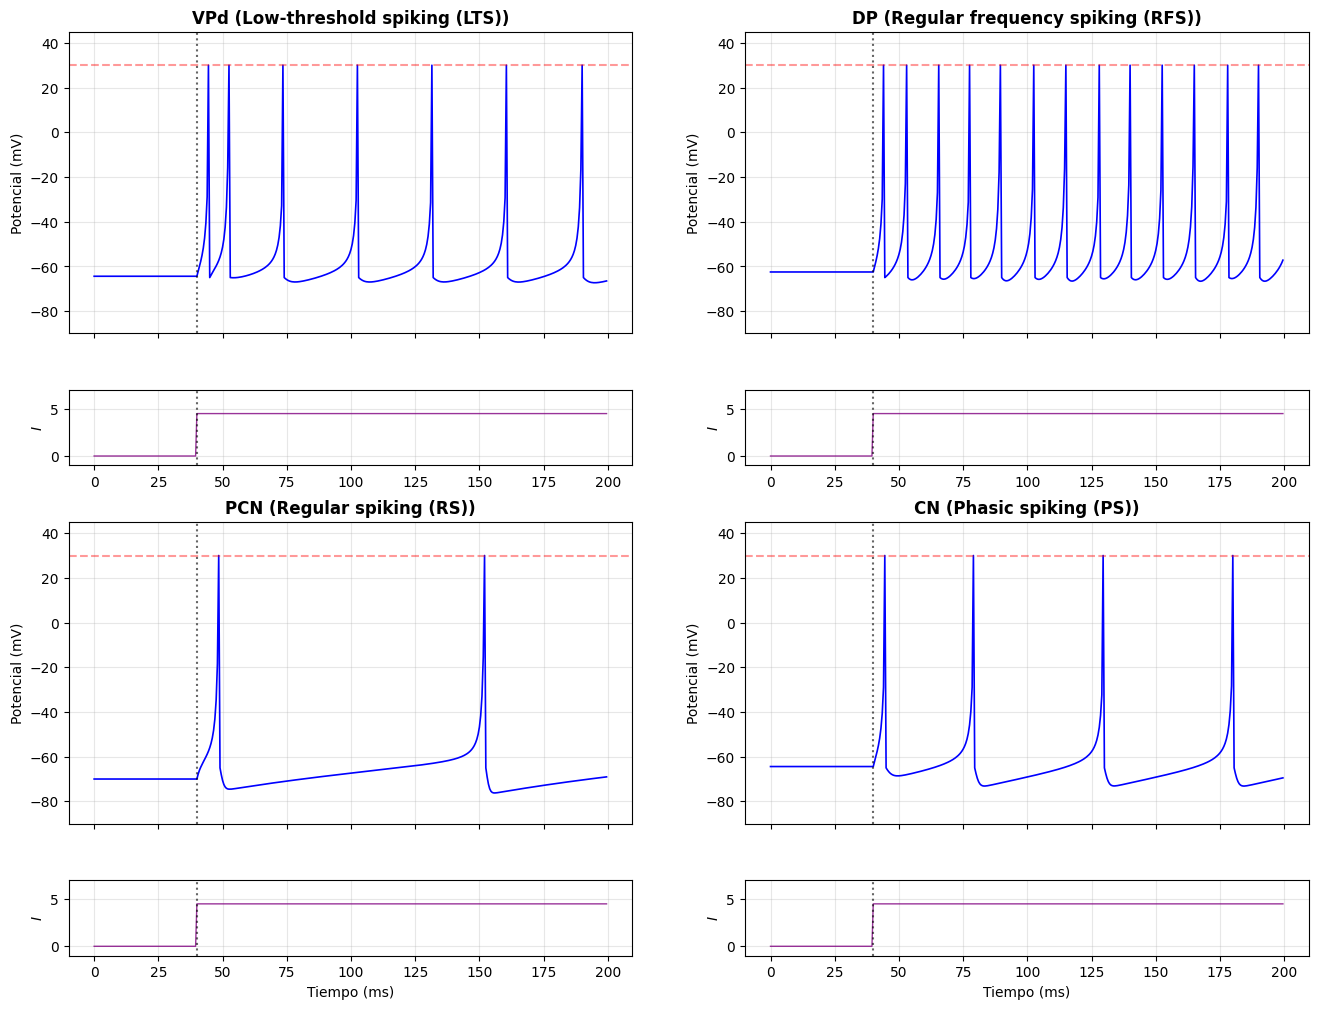

In [12]:
modelos = [
    {"titulo": "VPd (Low-threshold spiking (LTS))",  "a": 0.02, "b": 0.25, "c": -65.0, "d": 2.0},
    {"titulo": "DP (Regular frequency spiking (RFS))", "a": 0.1,  "b": 0.26, "c": -65.0, "d": 2.0},
    {"titulo": "PCN (Regular spiking (RS))",          "a": 0.02, "b": 0.2,  "c": -65.0, "d": 8.0},
    {"titulo": "CN (Phasic spiking (PS))",           "a": 0.02, "b": 0.25, "c": -65.0, "d": 6.0}
]

fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(4, 2, height_ratios=[4, 1, 4, 1], hspace=0.3, wspace=0.2)

posiciones = [
    {"v": (0, 0), "I": (1, 0)},
    {"v": (0, 1), "I": (1, 1)},
    {"v": (2, 0), "I": (3, 0)},
    {"v": (2, 1), "I": (3, 1)}
]

for i, mod in enumerate(modelos):
    pos = posiciones[i]
    
    tiempo, v, I = izhikevich(mod["a"], mod["b"], mod["c"], mod["d"])
    
    ax_v = fig.add_subplot(gs[pos["v"][0], pos["v"][1]])
    ax_v.plot(tiempo, v, color='blue', lw=1.2)
    ax_v.axhline(30, color='red', linestyle='--', alpha=0.4)
    ax_v.axvline(40.0, color='black', linestyle=':', alpha=0.6)
    
    ax_v.set_title(mod["titulo"], fontsize=12, fontweight='bold')
    ax_v.set_ylabel('Potencial (mV)')
    ax_v.set_ylim(-90, 45)
    ax_v.grid(True, alpha=0.3)
    ax_v.tick_params(axis='x', labelbottom=False) 
    
    ax_I = fig.add_subplot(gs[pos["I"][0], pos["I"][1]], sharex=ax_v)
    ax_I.plot(tiempo, I, color='purple', lw=1, alpha=0.8)
    ax_I.axvline(40.0, color='black', linestyle=':', alpha=0.6)
    
    ax_I.set_ylabel('$I$')
    ax_I.set_ylim(-1, 7)
    ax_I.grid(True, alpha=0.3)
    if pos["I"][0] == 3:
        ax_I.set_xlabel('Tiempo (ms)')
plt.tight_layout()
plt.subplots_adjust(hspace=0.4) 
plt.show()